## Import relevant libraries

In [12]:
from pathlib import Path
import ezdxf
from collections import Counter
import pandas as pd
import shutil
from helpers import *
from shapely.ops import unary_union

## Find all different entity-types in the DXF-dataset + count

In [3]:
total = Counter()
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"): 
    try:
        msp = ezdxf.readfile(f).modelspace()
        total.update(e.dxftype() for e in msp)
    except Exception as ex:
        print(f"Fehler bei {f.name}: {ex}")

print(total)

Counter({'LINE': 1814, 'CIRCLE': 530, 'ARC': 491, 'POINT': 63})


-> Objects of type "Line", "Circle" and "Arc" have to be taken into account for the DXF functions (LWPOLYLINE and POLYLINE are not relevant for this dataset). What's the function of "Points"? (Since they are not part of the cutting geometry maybe some kind of marker?).

## Get entity-types of all DXF files containing "Points"

In [ ]:
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    msp = ezdxf.readfile(f).modelspace()
    c = Counter(e.dxftype() for e in msp)
    if c["POINT"]:
        print(f.name, dict(c))

Geo (23).DXF {'ARC': 18, 'LINE': 52, 'POINT': 6}
Geo (9).DXF {'ARC': 10, 'CIRCLE': 4, 'LINE': 16, 'POINT': 2}
Geo (78).DXF {'ARC': 6, 'CIRCLE': 51, 'LINE': 11, 'POINT': 1}
Geo (14).DXF {'ARC': 27, 'LINE': 38, 'POINT': 2}
Geo (13).DXF {'ARC': 6, 'CIRCLE': 2, 'LINE': 13, 'POINT': 1}
Geo (25).DXF {'ARC': 27, 'CIRCLE': 5, 'LINE': 30, 'POINT': 5}
Geo (64).DXF {'CIRCLE': 8, 'ARC': 8, 'LINE': 102, 'POINT': 4}
Geo (65).DXF {'ARC': 22, 'LINE': 34, 'POINT': 10}
Geo (53).DXF {'CIRCLE': 6, 'ARC': 4, 'LINE': 41, 'POINT': 1}
Geo (12).DXF {'CIRCLE': 9, 'ARC': 4, 'LINE': 16, 'POINT': 2}
Geo (11).DXF {'ARC': 32, 'LINE': 42, 'POINT': 6}
Geo (66).DXF {'ARC': 20, 'LINE': 35, 'POINT': 7}
Geo (71).DXF {'CIRCLE': 1, 'ARC': 3, 'LINE': 10, 'POINT': 1}
Geo (10).DXF {'ARC': 14, 'LINE': 25, 'POINT': 5}
Geo (7).DXF {'ARC': 6, 'LINE': 13, 'POINT': 3}
Geo (57).DXF {'CIRCLE': 6, 'ARC': 44, 'LINE': 87, 'POINT': 5}
Geo (6).DXF {'ARC': 12, 'CIRCLE': 2, 'LINE': 25, 'POINT': 2}


## Test if POINTS are markers for centers of circles
test for 3 random DXF files

In [ ]:
for name in ["10991360/Geo (65).DXF", "10991360/Geo (78).DXF", "10991360/Geo (13).DXF"]:
    msp = ezdxf.readfile(name).modelspace()
    circles = [(c.dxf.center.x, c.dxf.center.y) for c in msp.query("CIRCLE")]
    print(name)
    for p in msp.query("POINT"):
        x, y = p.dxf.location.x, p.dxf.location.y
        d = min((((x - cx)**2 + (y - cy)**2) ** 0.5 for cx, cy in circles), default=None)
        print(f"  layer={p.dxf.layer} pos=({x:.2f}, {y:.2f}) Abstand zum nächsten Kreismittelpunkt: {d}")

10991360/Geo (65).DXF
  layer=0 pos=(39.70, 65.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(116.85, 71.85) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(212.48, 78.22) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(310.47, 67.81) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(391.05, 61.55) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(487.54, 54.74) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(576.94, 64.46) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(697.71, 62.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(752.72, 75.29) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(815.90, 62.79) Abstand zum nächsten Kreismittelpunkt: None
10991360/Geo (78).DXF
  layer=0 pos=(351.03, 143.89) Abstand zum nächsten Kreismittelpunkt: 48.770753046099905
10991360/Geo (13).DXF
  layer=0 pos=(88.11, 22.88) Abstand zum nächsten Kreismittelpunkt: 71.70466060645266


 -> Points are on the same layer as everything else and are not markers for centers of circles (Geo 65: no circles but still 10 Points)

## Plot the analysed DXF files

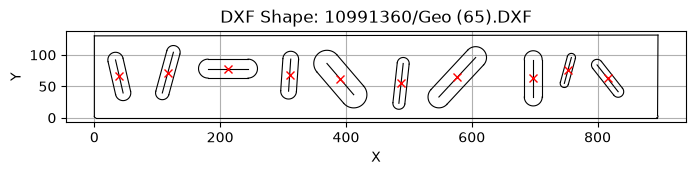

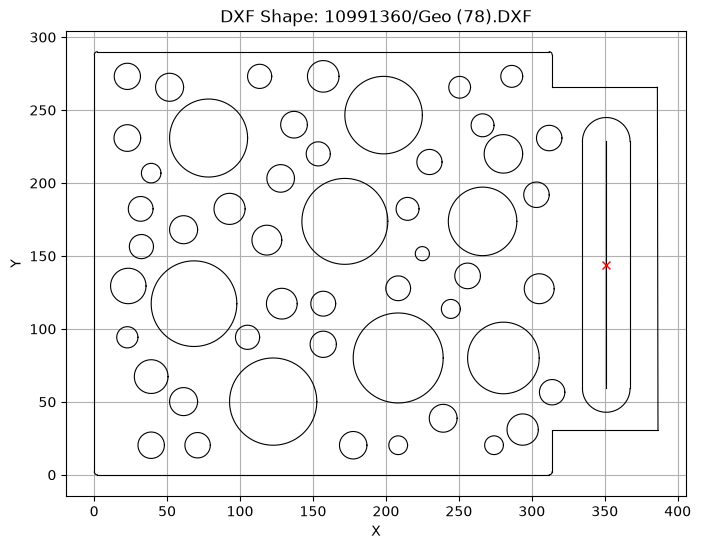

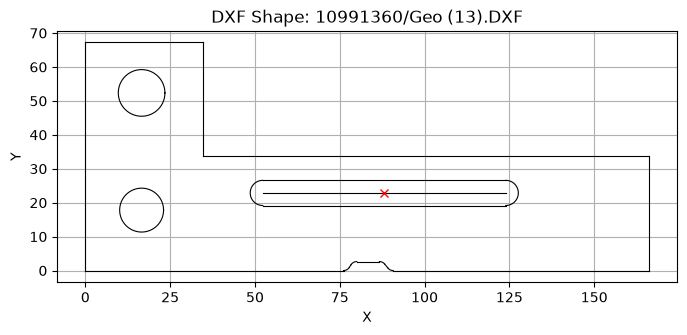

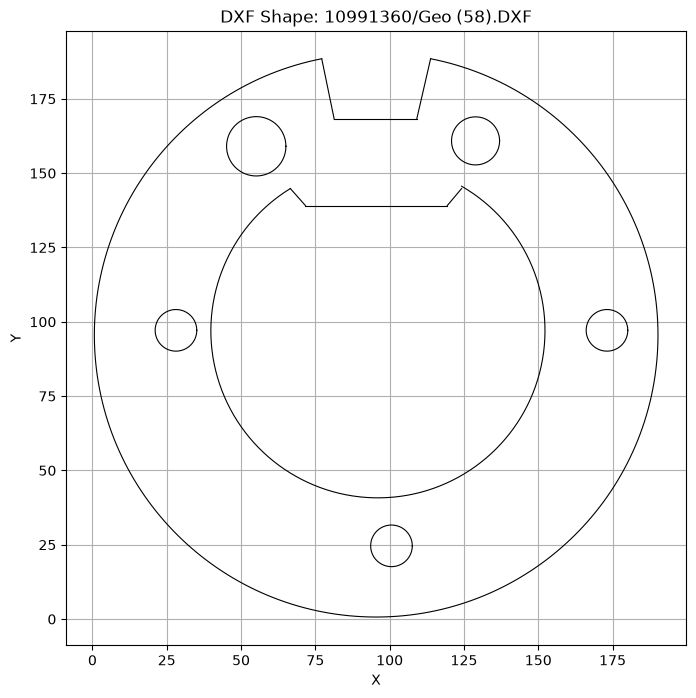

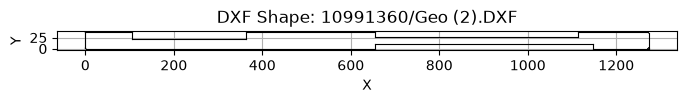

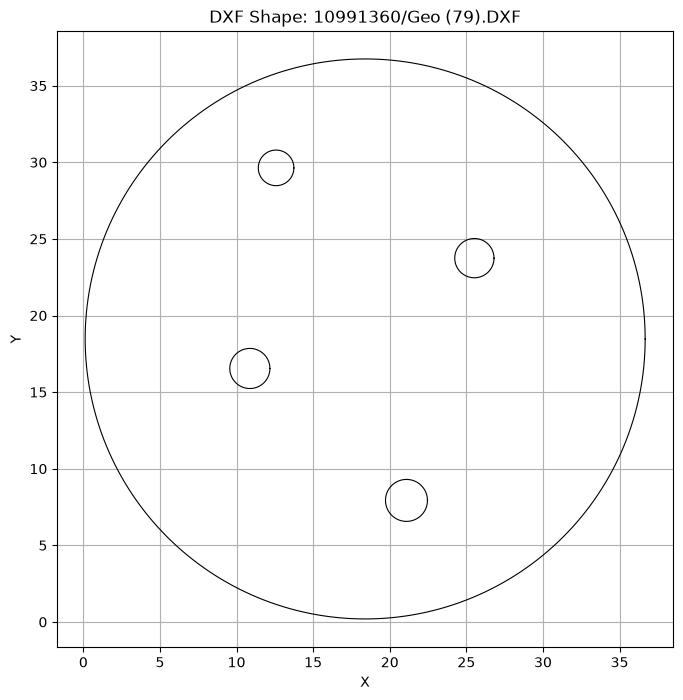

In [3]:
plot_dxf("10991360/Geo (65).DXF")
plot_dxf("10991360/Geo (78).DXF")
plot_dxf("10991360/Geo (13).DXF")

plot_dxf("10991360/Geo (58).DXF")
plot_dxf("10991360/Geo (2).DXF")
plot_dxf("10991360/Geo (79).DXF")

## Point location
#### Test for all DXF files containing "Points" in which layer their points are located

In [ ]:
for f in Path("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    points = get_point_context(f)                       
    lines = get_line_context(f) 
    if points or lines:
            flag = "" if len(points) == len(lines) else "   <-- Anzahl verschieden"
            print(f.name, "| POINTs:", points, "| unconnected LINEs:", lines, flag)


Geo (23).DXF | POINTs: [1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1] 
Geo (9).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (78).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (14).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (13).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (25).DXF | POINTs: [1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1] 
Geo (64).DXF | POINTs: [1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1] 
Geo (65).DXF | POINTs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 
Geo (53).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (12).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (11).DXF | POINTs: [1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1] 
Geo (66).DXF | POINTs: [1, 1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1, 1] 
Geo (71).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (10).DXF | POINTs: [1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1] 
Geo (7).DXF | POINTs: [1,

-> all points and lines are located in "scrap"-layers (layer 1)

-> Together with the three plotted DXF-files it's quite clear that "Points" and "unconnected LINEs" are markers for centers of ovals. Taking a closer look on the output we can also observe that the number of POINTs and unconnected LINEs is the same for each file.

For the helper functions and the further EDA this has the following consequences: "Points" are irrelevant for any calculation of cutting length, bounding box or number of holes. "Unconnected lines" (Meaning lines which are not connected to any ARCs, CIRCLEs or other LINEs) are also irrelevant for the cutting process (since they'll be removed with the scrap) and therefore should NOT be taken into account when calculating cutting length.

## Check further DXF problems
1. Overlapping geometries, Duplicates
2. Mirrored entities
3. Protrusions, Gaps
4. Overlapping scrap surfaces

In [2]:
def count_free_endpoints(path, tol=0.01):
    """Endpunkte von LINE/ARC ohne Gegenstück. Erwartung: 2 pro Markierungslinie."""
    msp = ezdxf.readfile(path).modelspace()
    ends = []
    for i, e in enumerate(msp):
        if e.dxftype() == "LINE":
            ends += [(i, e.dxf.start), (i, e.dxf.end)]
        elif e.dxftype() == "ARC":
            ends += [(i, e.start_point), (i, e.end_point)]
    return sum(
        1 for i, p in ends
        if not any(j != i and math.dist((p.x, p.y), (q.x, q.y)) <= tol for j, q in ends)
    )

def overlap_length(path):
    """Summe der Einzellängen minus Länge der vereinigten Linien (>0: Duplikate/Überlappung)."""
    msp = ezdxf.readfile(path).modelspace()
    lines = [LineString(flatten(e)) for e in msp if e.dxftype() in ("LINE", "ARC", "CIRCLE")]
    return sum(l.length for l in lines) - unary_union(lines).length

attrs, extrusion = Counter(), Counter()
rows = []
for f in sorted(Path("../Challenge1/10991360").glob("*.[dD][xX][fF]")):
    doc = ezdxf.readfile(f)
    msp = doc.modelspace()
    for e in msp:
        attrs[(e.dxftype(), e.dxf.layer, e.dxf.linetype, e.dxf.color)] += 1
        if e.dxftype() in ("ARC", "CIRCLE"):
            extrusion[tuple(round(v, 6) for v in e.dxf.extrusion)] += 1
    n_points = len(msp.query("POINT"))
    faces = get_faces(f)
    parts = sum(1 for _, d in faces if d % 2 == 0)
    rows.append({
        "file": f.name,
        "units": doc.units,
        "paperspace": sum(len(l) for l in doc.layouts if l.name != "Model"),
        "overlap_len": overlap_length(f),
        "free_ends_extra": count_free_endpoints(f) - 2 * n_points,
        "face_mismatch": len(faces) - (parts + get_number_of_holes(f)),
        "z_nonzero": sum(1 for e in msp.query("LINE")
                         if abs(e.dxf.start.z) > 1e-9 or abs(e.dxf.end.z) > 1e-9),
    })
chk = pd.DataFrame(rows)

print(attrs)        # Layer/Linientyp/Farbe: nur (…, "0", "Continuous", 7)?
print(extrusion)    # nur (0, 0, 1)?
print(chk.units.value_counts())
print(chk[(chk.overlap_len > 0.01) | (chk.free_ends_extra != 0) | (chk.face_mismatch != 0)
          | (chk.paperspace > 0) | (chk.z_nonzero > 0)])

Counter({('LINE', '0', 'Continuous', 7): 1751, ('CIRCLE', '0', 'Continuous', 7): 530, ('ARC', '0', 'Continuous', 7): 491, ('LINE', '0', 'CENTERX2', 7): 63, ('POINT', '0', 'Continuous', 7): 63})
Counter({(0.0, 0.0, 1.0): 1021})
units
4    80
Name: count, dtype: int64
            file  units  paperspace   overlap_len  free_ends_extra  \
11   Geo (2).DXF      4           0  4.547474e-13                2   
53  Geo (58).DXF      4           0  0.000000e+00                2   

    face_mismatch  z_nonzero  
11              0          0  
53              0          0  


-> for two DXF files, gaps have occured between entities

## Print out these files and their gaps

Geo (2).DXF Löcher: 0 [('LINE', 1273.0, -1.0, 1.4142), ('LINE', 1274.0, 0.0, 1.4142)]


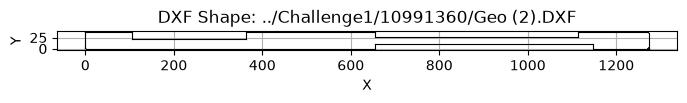

Geo (58).DXF Löcher: 6 [('ARC', 124.194, 145.612, 0.7821), ('LINE', 124.194, 144.83, 0.7821)]


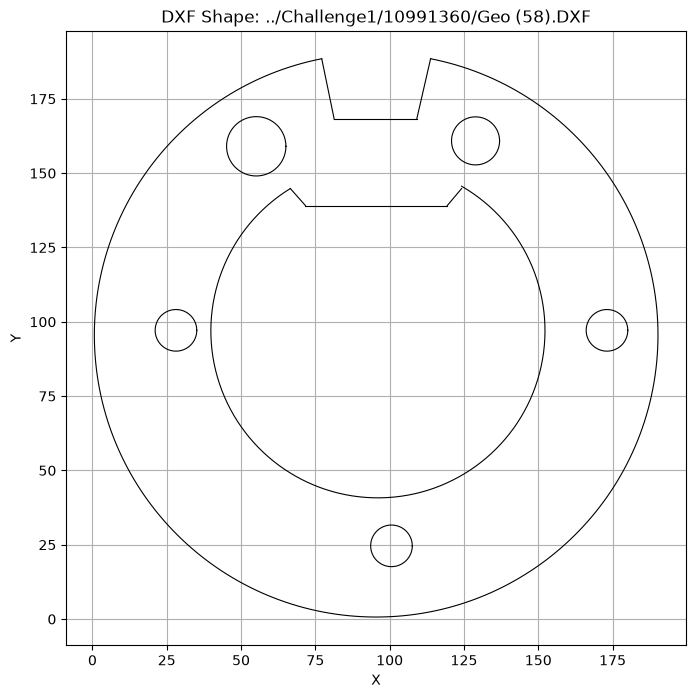

In [3]:
def free_endpoints(path, tol=0.01):
    msp = ezdxf.readfile(path).modelspace()
    ends = []
    for i, e in enumerate(msp):
        t = e.dxftype()
        if t == "LINE":
            pts = (e.dxf.start, e.dxf.end)
        elif t == "ARC":
            pts = (e.start_point, e.end_point)
        else:
            continue
        ends += [(i, t, p) for p in pts]
    out = []
    for i, t, p in ends:
        d = min((math.dist((p.x, p.y), (q.x, q.y)) for j, _, q in ends if j != i), default=None)
        if d is not None and d > tol:
            out.append((t, round(p.x, 3), round(p.y, 3), round(d, 4)))
    return out

for name in ["Geo (2).DXF", "Geo (58).DXF"]:
    p = Path("../Challenge1/10991360") / name
    print(name, "Löcher:", get_number_of_holes(p), free_endpoints(p))
    plot_dxf(p)

In [4]:
def debug_bridges(path):
    doc = ezdxf.readfile(path)
    lines = [LineString(flatten(e)) for e in doc.modelspace()
             if e.dxftype() in ("LINE", "ARC", "CIRCLE")
             and not (e.dxftype() == "LINE" and "CENTER" in e.dxf.linetype.upper())]
    return len(bridge_gaps(lines)) - len(lines)

for name in ["Geo (58).DXF", "Geo (2).DXF", "Geo (29).DXF"]:
    p = Path("../Challenge1/10991360") / name
    print(name, "| Brücken:", debug_bridges(p),
          "| Löcher:", get_number_of_holes(p), "| Teile:", get_number_of_parts(p)[1])

Geo (58).DXF | Brücken: 1 | Löcher: 6 | Teile: 1
Geo (2).DXF | Brücken: 1 | Löcher: 0 | Teile: 3
Geo (29).DXF | Brücken: 0 | Löcher: 7 | Teile: 1


In [5]:
def debug_endpoints(path):
    doc = ezdxf.readfile(path)
    lines = [LineString(flatten(e)) for e in doc.modelspace()
             if e.dxftype() in ("LINE", "ARC", "CIRCLE")
             and not (e.dxftype() == "LINE" and "CENTER" in e.dxf.linetype.upper())]
    ends = [c for l in lines if l.coords[0] != l.coords[-1] for c in (l.coords[0], l.coords[-1])]
    pairs = [(a, b) for k, a in enumerate(ends) for b in ends[k + 1:]]
    exact = sum(1 for a, b in pairs if a == b)
    noise = sum(1 for a, b in pairs if a != b and math.dist(a, b) <= 1e-3)
    faces = list(polygonize(unary_union(lines)))
    return {"exakt": exact, "rauschen": noise, "flächen": len(faces),
            "größte_fläche": round(max((f.area for f in faces), default=0), 1)}

for name in ["Geo (29).DXF", "Geo (58).DXF"]:
    print(name, debug_endpoints(Path("../Challenge1/10991360") / name))

Geo (29).DXF {'exakt': 16, 'rauschen': 0, 'flächen': 8, 'größte_fläche': 6614.1}
Geo (58).DXF {'exakt': 7, 'rauschen': 0, 'flächen': 6, 'größte_fläche': 26559.9}


In [6]:
for name in ["Geo (2).DXF", "Geo (5).DXF",
             "Geo (56).DXF", "Geo (58).DXF",
             "Geo (72).DXF", "Geo (79).DXF"]:
    p = Path("../Challenge1/10991360") / name
    debug_faces(p)


Geo (2).DXF
Anzahl polygonisierter Flächen: 3
Face 00 | Depth: 0 | Typ: Teil | Fläche: 33743.245 | Innenringe: 0 | Gültig: True
Face 01 | Depth: 0 | Typ: Teil | Fläche: 0.859 | Innenringe: 0 | Gültig: True
Face 02 | Depth: 0 | Typ: Teil | Fläche: 0.500 | Innenringe: 0 | Gültig: True
------------------------------------------------------------
Teile: 3
Löcher: 0

Geo (5).DXF
Anzahl polygonisierter Flächen: 15
Face 00 | Depth: 0 | Typ: Teil | Fläche: 9261.239 | Innenringe: 14 | Gültig: True
Face 01 | Depth: 1 | Typ: Loch | Fläche: 12802.338 | Innenringe: 0 | Gültig: True
Face 02 | Depth: 1 | Typ: Loch | Fläche: 38.387 | Innenringe: 0 | Gültig: True
Face 03 | Depth: 1 | Typ: Loch | Fläche: 115.903 | Innenringe: 0 | Gültig: True
Face 04 | Depth: 1 | Typ: Loch | Fläche: 128.896 | Innenringe: 0 | Gültig: True
Face 05 | Depth: 1 | Typ: Loch | Fläche: 169.054 | Innenringe: 0 | Gültig: True
Face 06 | Depth: 1 | Typ: Loch | Fläche: 21.256 | Innenringe: 0 | Gültig: True
Face 07 | Depth: 1 | Typ:

In [8]:
for name in ["Geo (2)_rounded.DXF", "Geo (58).DXF", "Geo (79).DXF"]:
    debug_polygonize(
        Path("../Challenge1/10991360") / name
    )


Geo (2)_rounded.DXF
Ursprüngliche Linien: 20
Erzeugte Brücken: 0
Polygonisierte Flächen: 1
Dangles: 0
Cuts: 0
Invalid rings: 0
Polygon 0: Fläche=33743.245, Innenringe=0

Geo (58).DXF
Ursprüngliche Linien: 13
Erzeugte Brücken: 1
Bridge 0: [(124.194, 145.612), (124.194, 144.83)], Länge: 0.7820
Polygonisierte Flächen: 7
Dangles: 0
Cuts: 0
Invalid rings: 0
Polygon 0: Fläche=9288.633, Innenringe=0
Polygon 1: Fläche=17271.288, Innenringe=6
Polygon 2: Fläche=313.082, Innenringe=0
Polygon 3: Fläche=205.287, Innenringe=0
Polygon 4: Fläche=153.968, Innenringe=0
Polygon 5: Fläche=153.968, Innenringe=0
Polygon 6: Fläche=153.968, Innenringe=0

Geo (79).DXF
Ursprüngliche Linien: 5
Erzeugte Brücken: 0
Polygonisierte Flächen: 5
Dangles: 0
Cuts: 0
Invalid rings: 0
Polygon 0: Fläche=4.246, Innenringe=0
Polygon 1: Fläche=5.163, Innenringe=0
Polygon 2: Fläche=5.386, Innenringe=0
Polygon 3: Fläche=5.896, Innenringe=0
Polygon 4: Fläche=1029.000, Innenringe=4


In [9]:
inspect_small_faces(
    Path("../Challenge1/10991360/Geo (2).DXF")
)


Polygon 0
Fläche: 33743.245477
Umfang: 2692.517613
Bounds: (0.0, 0.0, 1273.0, 37.643)
Koordinaten:
(0.0, 36.643)
(0.001, 36.695)
(0.005, 36.745)
(0.012, 36.796)
(0.02, 36.845)
(0.031, 36.893)
(0.045, 36.941)
(0.061, 36.987)
(0.079, 37.032)
(0.099, 37.077)
(0.121, 37.12)
(0.145, 37.162)
(0.171, 37.202)
(0.199, 37.242)
(0.228, 37.279)
(0.26, 37.316)
(0.293, 37.35)
(0.328, 37.383)
(0.364, 37.415)
(0.402, 37.445)
(0.441, 37.472)
(0.481, 37.498)
(0.523, 37.523)
(0.566, 37.545)
(0.611, 37.565)
(0.656, 37.583)
(0.703, 37.598)
(0.75, 37.612)
(0.798, 37.623)
(0.848, 37.632)
(0.898, 37.638)
(0.949, 37.642)
(1.0, 37.643)
(105.932, 37.643)
(105.932, 22.389)
(363.974, 22.389)
(363.974, 37.643)
(655.498, 37.643)
(655.498, 25.909)
(1112.887, 25.909)
(1112.887, 37.643)
(1271.0, 37.643)
(1271.103, 37.641)
(1271.204, 37.633)
(1271.305, 37.62)
(1271.403, 37.603)
(1271.5, 37.58)
(1271.595, 37.553)
(1271.688, 37.522)
(1271.778, 37.486)
(1271.867, 37.446)
(1271.953, 37.402)
(1272.037, 37.354)
(1272.118, 37

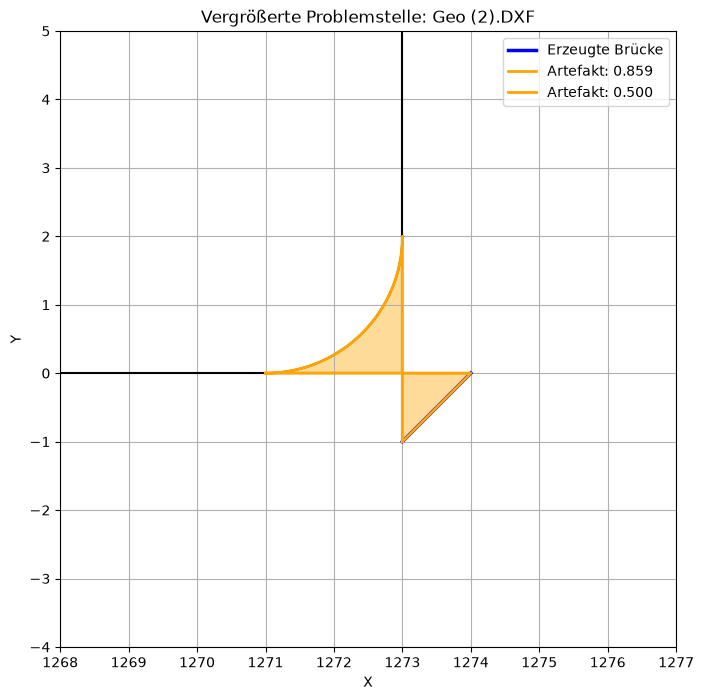

In [10]:
plot_problem_area(
    Path("../Challenge1/10991360/Geo (2).DXF")
)

In [13]:
# Quell- und Zielordner
source = Path("../Challenge1/10991360")
target = Path("../Challenge1/10991360_editet")

# Gesamten Ordner kopieren
shutil.copytree(source, target, dirs_exist_ok=True)

# Geo (2).DXF im neuen Ordner bearbeiten
path = target / "Geo (2).DXF"

doc = ezdxf.readfile(path)
msp = doc.modelspace()

# Überflüssige Liniensegmente an der Verrundung
segments = [
    ((1271, 0), (1274, 0)),
    ((1273, -1), (1273, 2))
]

# Linien entfernen
for e in list(msp.query("LINE")):
    start = (e.dxf.start.x, e.dxf.start.y)
    end = (e.dxf.end.x, e.dxf.end.y)

    for p1, p2 in segments:
        if (
            (math.dist(start, p1) < 0.01 and math.dist(end, p2) < 0.01)
            or
            (math.dist(start, p2) < 0.01 and math.dist(end, p1) < 0.01)
        ):
            msp.delete_entity(e)
            print(f"Entfernt: {start} -> {end}")
            break

# Unter demselben Dateinamen speichern
doc.saveas(path)

Entfernt: (1273.0, 2.0) -> (1273.0, -1.0)
Entfernt: (1271.0, 0.0) -> (1274.0, 0.0)


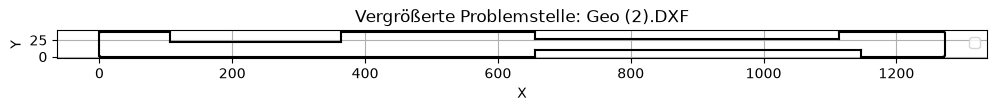

In [14]:
plot_problem_area(
    Path("../Challenge1/10991360_editet/Geo (2).DXF")
)